In [1]:
!pip install "pulp<4"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 37.6 MB/s eta 0:00:00
  Attempting uninstall: pulp
    Found existing installation: PuLP 4.0.0
    Uninstalling PuLP-4.0.0:
      Successfully uninstalled PuLP-4.0.0


# 💰 Kişisel Bütçe ve Harcama Optimizasyonu
**Endüstri Mühendisliği Portföy Projesi** | Python · Pandas · Seaborn · PuLP

**Problem:** Aylık geliri 15.000 TL olan bir kişi 5.000 TL biriktirmek istiyor. Mevcut harcama alışkanlıklarından
*mümkün olduğunca az sapacak* şekilde, kategori bazlı yeni harcama limitleri belirlenmelidir.

**Yöntem:** Doğrusal Programlama (LP) – Minimizasyon modeli (mutlak sapmanın doğrusallaştırılması)

**İçindekiler**
1. Veri seti oluşturma
2. Keşifsel veri analizi ve görselleştirme
3. Optimizasyon modeli (PuLP)
4. Sonuçların karşılaştırılması

In [2]:
# Gerekli kütüphaneler
# PuLP kurulu değilse (klasik API için 4.x öncesi sürüm önerilir): !pip install "pulp<4"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pulp

# Görsel ayarlar
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.2f}".format

## 1️⃣ Veri Seti Oluşturma

In [3]:
# Sonuçların her çalıştırmada aynı çıkması için rastgelelik tohumu (seed) sabitlenir
rng = np.random.default_rng(42)

# 3 aylık (Temmuz-Eylül 2026) örnek harcama verisi üretilir
aylar = pd.period_range("2026-07", "2026-09", freq="M")

# Her kategori için: (aylık işlem sayısı, ortalama tutar, standart sapma)
# Gıda ~4.800 TL, Ulaşım ~2.400 TL, Eğlence ~1.800 TL olacak şekilde ayarlandı
kategori_parametreleri = {
    "Gıda":    (24, 200, 40),
    "Ulaşım":  (20, 120, 25),
    "Eğlence": (6,  300, 90),
}

kayitlar = []
for ay in aylar:
    gun_sayisi = ay.days_in_month

    # Değişken harcamalar: rastgele günlere dağıtılmış işlemler
    for kategori, (adet, ort, std) in kategori_parametreleri.items():
        gunler = rng.integers(1, gun_sayisi + 1, size=adet)
        tutarlar = rng.normal(ort, std, size=adet).clip(min=20).round(2)
        for gun, tutar in zip(gunler, tutarlar):
            kayitlar.append((pd.Timestamp(ay.year, ay.month, int(gun)), kategori, tutar))

    # Faturalar: her ay sabit günlerde ödenen 4 fatura (küçük dalgalanmayla)
    for gun, baz in zip([5, 10, 15, 20], [1200, 800, 500, 300]):
        kayitlar.append((pd.Timestamp(ay.year, ay.month, gun), "Faturalar",
                         round(baz + rng.normal(0, 15), 2)))

df = pd.DataFrame(kayitlar, columns=["Tarih", "Kategori", "Tutar"])
df = df.sort_values("Tarih").reset_index(drop=True)

print(f"Toplam kayıt sayısı: {len(df)}")
df.head(10)

Toplam kayıt sayısı: 162


,Tarih,Kategori,Tutar
0,2026-07-01,Eğlence,217.25
1,2026-07-03,Gıda,202.64
2,2026-07-03,Gıda,172.76
3,2026-07-03,Gıda,235.14
4,2026-07-03,Eğlence,258.39
5,2026-07-04,Ulaşım,98.35
6,2026-07-04,Gıda,217.23
7,2026-07-05,Ulaşım,108.24
8,2026-07-05,Faturalar,"1,207.46"
9,2026-07-05,Ulaşım,125.47


## 2️⃣ Keşifsel Veri Analizi ve Görselleştirme

In [4]:
# Kategori bazında toplam harcama (3 ay) ve aylık ortalama
ozet = df.groupby("Kategori")["Tutar"].agg(["sum", "mean", "count"])
ozet.columns = ["Toplam (3 Ay)", "İşlem Başına Ort.", "İşlem Sayısı"]

# Optimizasyonda kullanılacak "mevcut aylık harcama" = 3 aylık toplam / 3
ozet["Aylık Ortalama"] = ozet["Toplam (3 Ay)"] / len(aylar)
ozet["Pay (%)"] = ozet["Toplam (3 Ay)"] / ozet["Toplam (3 Ay)"].sum() * 100
ozet = ozet.sort_values("Aylık Ortalama", ascending=False)
ozet

,Toplam (3 Ay),İşlem Başına Ort.,İşlem Sayısı,Aylık Ortalama,Pay (%)
Kategori,,,,,
Gıda,"14,426.30",200.37,72,"4,808.77",40.80
Faturalar,"8,398.86",699.91,12,"2,799.62",23.75
Ulaşım,"7,160.53",119.34,60,"2,386.84",20.25
Eğlence,"5,375.17",298.62,18,"1,791.72",15.20


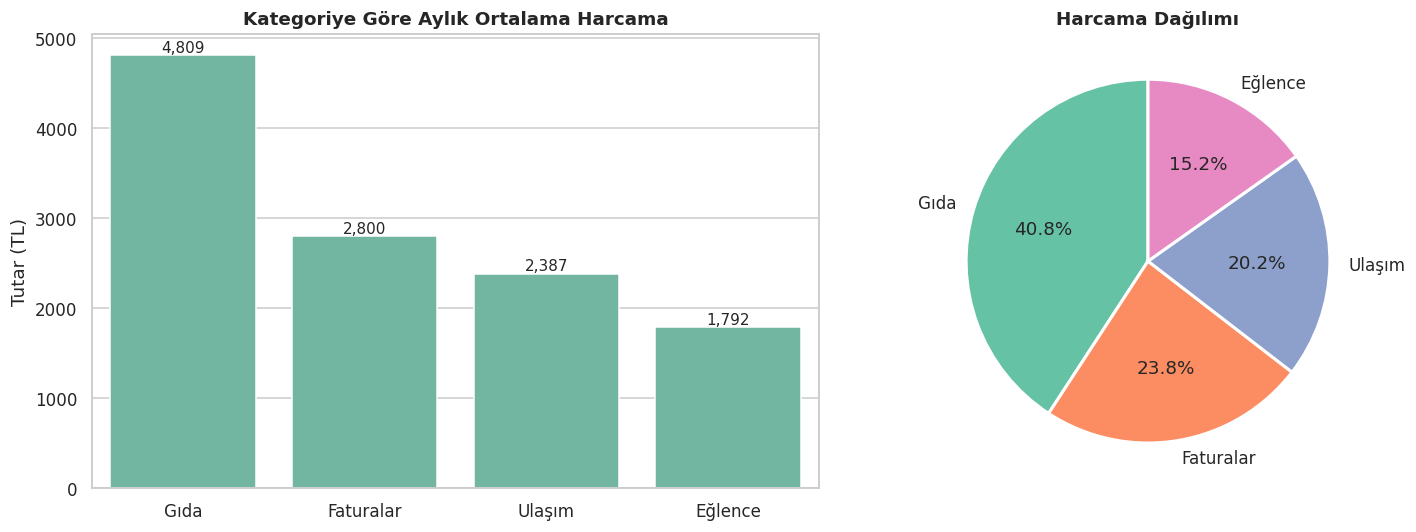

In [5]:
# Yan yana iki grafik: sütun grafiği + pasta grafiği
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# --- Sütun grafiği: aylık ortalama harcama ---
sns.barplot(x=ozet.index, y=ozet["Aylık Ortalama"], ax=ax[0])
ax[0].set_title("Kategoriye Göre Aylık Ortalama Harcama", fontweight="bold")
ax[0].set_xlabel("")
ax[0].set_ylabel("Tutar (TL)")
for p in ax[0].patches:   # Çubukların üstüne değer etiketi
    ax[0].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width()/2, p.get_height()),
                   ha="center", va="bottom", fontsize=10)

# --- Pasta grafiği: harcama dağılımı ---
ax[1].pie(ozet["Toplam (3 Ay)"], labels=ozet.index, autopct="%1.1f%%",
          startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2})
ax[1].set_title("Harcama Dağılımı", fontweight="bold")

plt.tight_layout()
plt.show()

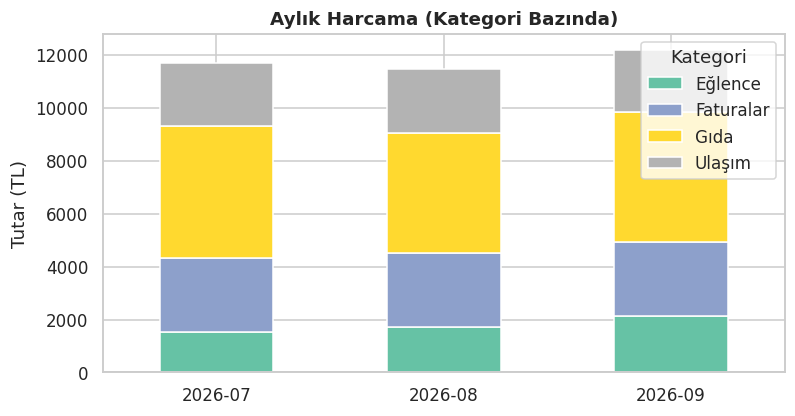

Mevcut aylık toplam harcama: 11,786.95 TL


In [6]:
# Aylık toplam harcama trendi
aylik = df.groupby([df["Tarih"].dt.to_period("M").astype(str), "Kategori"])["Tutar"].sum().unstack()
aylik.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="Set2")
plt.title("Aylık Harcama (Kategori Bazında)", fontweight="bold")
plt.ylabel("Tutar (TL)"); plt.xlabel(""); plt.xticks(rotation=0)
plt.show()

print(f"Mevcut aylık toplam harcama: {ozet['Aylık Ortalama'].sum():,.2f} TL")

## 3️⃣ Optimizasyon Modeli (PuLP)

### Matematiksel Model
**Karar değişkenleri:** $x_i$ = kategori $i$ için yeni aylık harcama limiti (TL)

**Mevcut harcamalar:** $a_i$ (veri setinden hesaplanan aylık ortalama)

**Amaç fonksiyonu (min):** Mevcut harcamalardan *göreli* sapmaların toplamı

$$\min \sum_i \frac{d_i}{a_i}, \qquad d_i \ge x_i - a_i, \quad d_i \ge a_i - x_i$$

> $|x_i - a_i|$ doğrusal değildir. $d_i$ yardımcı değişkenleri ile **doğrusallaştırılır**; minimizasyon $d_i$'yi sapmanın mutlak değerine eşitler.
> Sapmayı $a_i$'ye bölmek, yüzdesel kayba göre ağırlıklandırma yapar: küçük bütçeli kategoriden kesmek, yaşam kalitesini orantılı olarak daha çok etkiler.

**Kısıtlar:** Gıda ≥ 4.000 · Ulaşım ≥ 1.500 · Eğlence ≥ 500 · Faturalar = 2.500 · Toplam ≤ 10.000

In [7]:
# ---------------- PARAMETRELER ----------------
GELIR = 15_000          # Aylık toplam gelir (TL)
HEDEF_BIRIKIM = 5_000   # Hedeflenen aylık birikim (TL)
MAX_HARCAMA = GELIR - HEDEF_BIRIKIM   # = 10.000 TL (harcama üst limiti)

# Mevcut aylık harcamalar (a_i) - EDA adımında hesaplanan değerler
mevcut = ozet["Aylık Ortalama"].to_dict()
kategoriler = list(mevcut.keys())

# Alt sınırlar (kategori bazlı minimum harcamalar)
alt_sinir = {"Gıda": 4_000, "Ulaşım": 1_500, "Eğlence": 500}
# Sabit değer (eşitlik kısıtı) olan kategori
sabit = {"Faturalar": 2_500}

print("Harcama üst limiti:", MAX_HARCAMA, "TL")
print("Mevcut harcamalar:", {k: round(v, 2) for k, v in mevcut.items()})

Harcama üst limiti: 10000 TL
Mevcut harcamalar: {'Gıda': 4808.77, 'Faturalar': 2799.62, 'Ulaşım': 2386.84, 'Eğlence': 1791.72}


In [8]:
# ---------------- MODEL TANIMI ----------------
# Minimizasyon problemi oluşturulur
model = pulp.LpProblem("Kisisel_Butce_Optimizasyonu", pulp.LpMinimize)

# KARAR DEĞİŞKENLERİ
# x[k]: kategori k için yeni harcama limiti (alt sınır 0 -> negatif olamaz, sürekli değişken)
x = pulp.LpVariable.dicts("Yeni_Harcama", kategoriler, lowBound=0, cat="Continuous")

# YARDIMCI DEĞİŞKENLER
# d[k]: mutlak sapma |x[k] - mevcut[k]| (doğrusallaştırma için)
d = pulp.LpVariable.dicts("Sapma", kategoriler, lowBound=0, cat="Continuous")

# AMAÇ FONKSİYONU
# Mevcut harcamalardan göreli (yüzdesel) toplam sapmayı minimize et
model += pulp.lpSum((1 / mevcut[k]) * d[k] for k in kategoriler), "Toplam_Goreli_Sapma"

# SAPMA KISITLARI (mutlak değerin doğrusallaştırılması)
for k in kategoriler:
    model += d[k] >= x[k] - mevcut[k], f"Sapma_Ust_{k}"   # artış yönündeki sapma
    model += d[k] >= mevcut[k] - x[k], f"Sapma_Alt_{k}"   # azalış yönündeki sapma

# İŞ KISITLARI
# Minimum harcama düzeyleri (yaşam kalitesinin korunması)
for k, limit in alt_sinir.items():
    model += x[k] >= limit, f"Min_{k}"

# Sabit giderler (faturalar değiştirilemez)
for k, deger in sabit.items():
    model += x[k] == deger, f"Sabit_{k}"

# Birikim hedefi: toplam harcama <= Gelir - Hedef Birikim
model += pulp.lpSum(x[k] for k in kategoriler) <= MAX_HARCAMA, "Toplam_Harcama_Limiti"

# ---------------- ÇÖZÜM ----------------
model.solve(pulp.PULP_CBC_CMD(msg=False))   # CBC çözücüsü, çıktıyı sessize al

print("Çözüm durumu :", pulp.LpStatus[model.status])
print("Amaç değeri  :", round(pulp.value(model.objective), 4))

Çözüm durumu : Optimal
Amaç değeri  : 0.5595


## 4️⃣ Sonuçların Karşılaştırılması

In [9]:
# Karşılaştırma tablosu
sonuc = pd.DataFrame({
    "Mevcut (TL)": [mevcut[k] for k in kategoriler],
    "Optimize (TL)": [x[k].value() for k in kategoriler],
}, index=kategoriler)

sonuc["Değişim (TL)"] = sonuc["Optimize (TL)"] - sonuc["Mevcut (TL)"]
sonuc["Değişim (%)"] = sonuc["Değişim (TL)"] / sonuc["Mevcut (TL)"] * 100
sonuc.loc["TOPLAM"] = [sonuc["Mevcut (TL)"].sum(), sonuc["Optimize (TL)"].sum(),
                       sonuc["Değişim (TL)"].sum(),
                       sonuc["Değişim (TL)"].sum() / sonuc["Mevcut (TL)"].sum() * 100]
sonuc

,Mevcut (TL),Optimize (TL),Değişim (TL),Değişim (%)
Gıda,"4,808.77","4,000.00",-808.77,-16.82
Faturalar,"2,799.62","2,500.00",-299.62,-10.70
Ulaşım,"2,386.84","1,708.28",-678.57,-28.43
Eğlence,"1,791.72","1,791.72",-0.00,-0.00
TOPLAM,"11,786.95","10,000.00","-1,786.95",-15.16


In [10]:
# Özet çıktı
yeni_toplam = sonuc.loc["TOPLAM", "Optimize (TL)"]
print("=" * 50)
print(f"Gelir                  : {GELIR:>10,.2f} TL")
print(f"Mevcut toplam harcama  : {sonuc.loc['TOPLAM', 'Mevcut (TL)']:>10,.2f} TL")
print(f"Optimize toplam harcama: {yeni_toplam:>10,.2f} TL")
print(f"Gerçekleşen birikim    : {GELIR - yeni_toplam:>10,.2f} TL (hedef: {HEDEF_BIRIKIM:,} TL)")
print("=" * 50)

# Kısıtların sağlandığının doğrulanması
assert x["Gıda"].value() >= 4000 - 1e-6
assert x["Ulaşım"].value() >= 1500 - 1e-6
assert x["Eğlence"].value() >= 500 - 1e-6
assert abs(x["Faturalar"].value() - 2500) < 1e-6
assert yeni_toplam <= MAX_HARCAMA + 1e-6
print("✅ Tüm kısıtlar sağlanıyor.")

Gelir                  :  15,000.00 TL
Mevcut toplam harcama  :  11,786.95 TL
Optimize toplam harcama:  10,000.00 TL
Gerçekleşen birikim    :   5,000.00 TL (hedef: 5,000 TL)
✅ Tüm kısıtlar sağlanıyor.


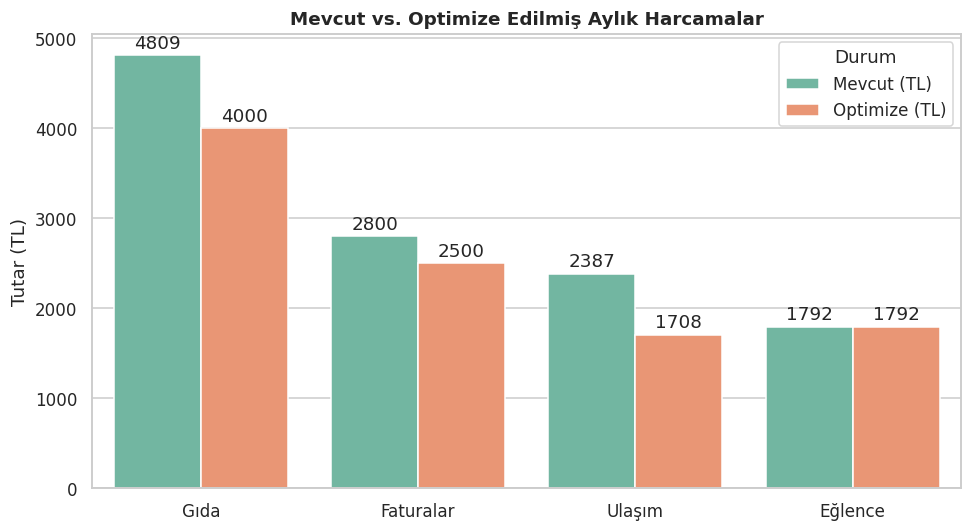

In [11]:
# Mevcut ve optimize harcamaların grafik karşılaştırması
grafik = sonuc.drop("TOPLAM")[["Mevcut (TL)", "Optimize (TL)"]].reset_index()
grafik = grafik.rename(columns={"index": "Kategori"}).melt(id_vars="Kategori", var_name="Durum", value_name="Tutar")

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=grafik, x="Kategori", y="Tutar", hue="Durum")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", padding=2)
plt.title("Mevcut vs. Optimize Edilmiş Aylık Harcamalar", fontweight="bold")
plt.ylabel("Tutar (TL)"); plt.xlabel("")
plt.tight_layout(); plt.show()

In [12]:
# Gölge fiyat (dual) analizi: bütçe limitinin 1 TL gevşetilmesinin amaç değerine etkisi
print("Kısıt gölge fiyatları (shadow price):")
for ad, kisit in model.constraints.items():
    if not ad.startswith("Sapma") and abs(kisit.pi or 0) > 1e-12:
        print(f"  {ad:<24} -> {kisit.pi:+.6f}")

Kısıt gölge fiyatları (shadow price):
  Min_Gıda                 -> +0.000211
  Sabit_Faturalar          -> +0.000062
  Toplam_Harcama_Limiti    -> -0.000419


## 📌 Yorum ve Sonuç
- Mevcut harcamalar 10.000 TL limitini aşmaktadır; model, birikim hedefine ulaşmak için gerekli kesintileri **yaşam kalitesini en az etkileyecek** şekilde dağıtmıştır.
- Faturalar sabit olduğundan değişmez; kesinti diğer kategorilerden yapılır.
- Gölge fiyat analizi, toplam harcama limitinin esnetilmesinin hedefe katkısını gösterir.

**Olası geliştirmeler:** kategori bazlı öncelik ağırlıkları, tam sayı (MILP) kısıtlar, çok dönemli bütçe planlaması, duyarlılık analizi.